In [51]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import OneHotEncoder,StandardScaler,MinMaxScaler
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor


In [52]:
data = pd.read_csv("/content/student_dataset_10000_rows.csv")

In [53]:
data

,study_hours,attendance,sleep_hours,internet_usage,assignments_completed,previous_score,exam_score,placement_status
0,7,56,8,7,10,62,100.00,Placed
1,4,69,5,3,8,56,100.00,Placed
2,11,60,7,6,10,45,100.00,Placed
3,8,99,9,8,4,55,90.17,Placed
4,5,52,8,6,8,40,78.82,Placed
...,...,...,...,...,...,...,...,...
9995,2,58,9,7,8,88,69.31,Not Placed
9996,7,98,6,9,4,87,100.00,Placed
9997,10,44,8,5,10,37,95.94,Placed
9998,10,75,7,5,8,52,88.61,Placed


In [54]:
data['placement_status'] = data['placement_status'].map({'Placed':1,'Not Placed':0})

In [55]:
data.columns

Index(['study_hours', 'attendance', 'sleep_hours', 'internet_usage',
       'assignments_completed', 'previous_score', 'exam_score',
       'placement_status'],
      dtype='object')

In [56]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 8 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   study_hours            10000 non-null  int64  
 1   attendance             10000 non-null  int64  
 2   sleep_hours            10000 non-null  int64  
 3   internet_usage         10000 non-null  int64  
 4   assignments_completed  10000 non-null  int64  
 5   previous_score         10000 non-null  int64  
 6   exam_score             10000 non-null  float64
 7   placement_status       10000 non-null  int64  
dtypes: float64(1), int64(7)
memory usage: 625.1 KB


In [57]:
data.describe()

,study_hours,attendance,sleep_hours,internet_usage,assignments_completed,previous_score,exam_score,placement_status
count,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000,10000.00000,10000.000000,10000.000000
mean,5.989600,69.88460,6.498500,6.062600,9.988400,64.91100,86.704207,0.835600
std,3.163589,17.61653,1.709354,3.138163,6.034145,17.50302,15.058383,0.370657
min,1.000000,40.00000,4.000000,1.000000,0.000000,35.00000,26.670000,0.000000
25%,3.000000,55.00000,5.000000,3.000000,5.000000,50.00000,76.727500,1.000000
50%,6.000000,70.00000,6.500000,6.000000,10.000000,65.00000,92.120000,1.000000
75%,9.000000,85.00000,8.000000,9.000000,15.000000,80.00000,100.000000,1.000000
max,11.000000,100.00000,9.000000,11.000000,20.000000,95.00000,100.000000,1.000000


In [58]:
#Features
X = data[
    ['study_hours', 'attendance', 'sleep_hours', 'internet_usage',
       'assignments_completed', 'previous_score', 'exam_score'
    ]
    ]

In [59]:
y = data['placement_status']

In [60]:
X

,study_hours,attendance,sleep_hours,internet_usage,assignments_completed,previous_score,exam_score
0,7,56,8,7,10,62,100.00
1,4,69,5,3,8,56,100.00
2,11,60,7,6,10,45,100.00
3,8,99,9,8,4,55,90.17
4,5,52,8,6,8,40,78.82
...,...,...,...,...,...,...,...
9995,2,58,9,7,8,88,69.31
9996,7,98,6,9,4,87,100.00
9997,10,44,8,5,10,37,95.94
9998,10,75,7,5,8,52,88.61


In [61]:
y

,placement_status
0,1
1,1
2,1
3,1
4,1
...,...
9995,0
9996,1
9997,1
9998,1


In [62]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42)

In [63]:
model = DecisionTreeRegressor(
    max_depth=5,
    random_state=42
)

In [64]:
model.fit(X_train,y_train)

DecisionTreeRegressor(max_depth=5, random_state=42)

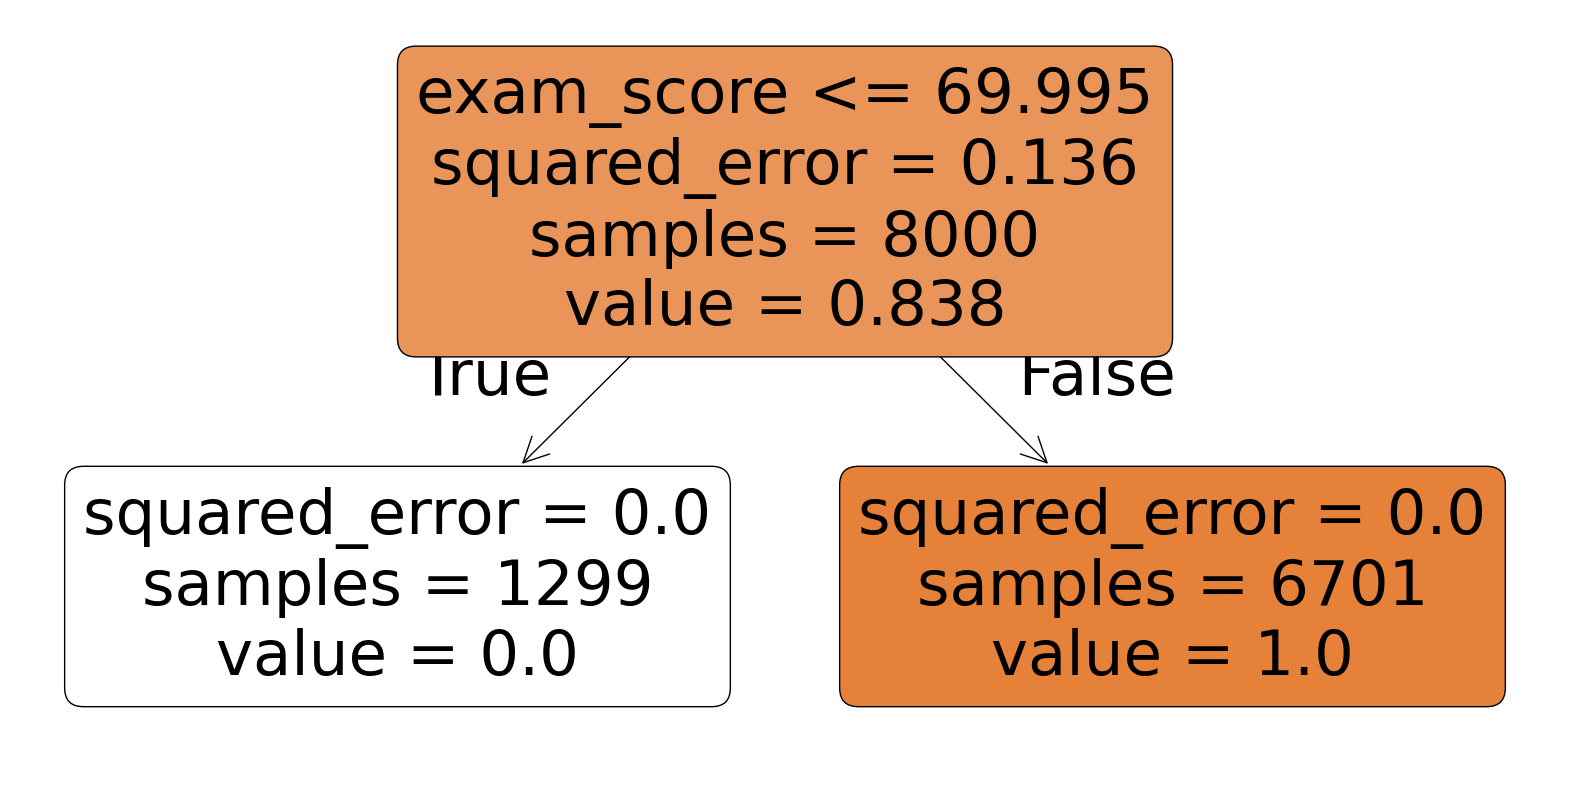

In [65]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

plt.figure(figsize=(20, 10))

plot_tree(
    model,
    feature_names=X.columns,
    filled=True,
    rounded=True
)

plt.show()


In [66]:
data

,study_hours,attendance,sleep_hours,internet_usage,assignments_completed,previous_score,exam_score,placement_status
0,7,56,8,7,10,62,100.00,1
1,4,69,5,3,8,56,100.00,1
2,11,60,7,6,10,45,100.00,1
3,8,99,9,8,4,55,90.17,1
4,5,52,8,6,8,40,78.82,1
...,...,...,...,...,...,...,...,...
9995,2,58,9,7,8,88,69.31,0
9996,7,98,6,9,4,87,100.00,1
9997,10,44,8,5,10,37,95.94,1
9998,10,75,7,5,8,52,88.61,1


In [70]:
new_student = [[
    12,
    70,
    9,
    7,
    8,
    20,
    20
]]

In [71]:
predicted_score = model.predict(new_student)

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeRegressor was fitted with feature names
  warnings.warn(


In [72]:
predicted_score

array([0.])